# U1 · Caídas significativas — Julmer Quispe Apaza

**Proyecto:** CryptoPulse · Grupo 3 · Big Data UPeU 2026-2
**Pregunta central del equipo:** ¿Cómo puede un analista de riesgo anticipar, con 5 a 30 minutos de antelación, condiciones de riesgo en BTC y SOL: volatilidad alta, caídas fuertes, actividad anómala y desacople entre ambos activos?

**Dimensión U1 (batch, descriptiva/diagnóstica + predictiva):** ¿Con qué frecuencia BTC y SOL tuvieron caídas fuertes a 30 minutos (dentro del 5 % de peores caídas de su historial) y en qué condiciones de mercado ocurren más, y qué probabilidad hay de una caída así en los próximos 30 minutos?

- **Indicador:** % mensual de ventanas de 30 min con rendimiento ≤ P5 histórico; probabilidad de caída estimada por un modelo de clasificación.
- **Decisión que habilita:** Reducir exposición o vigilar más de cerca cuando la probabilidad de caída supera el umbral.
- **Fuente batch:** Binance Public Data, velas de 1 minuto BTCUSDT y SOLUSDT, enero 2022 – septiembre 2026 (4 993 759 filas, ZIP con SHA256 verificado).
- **Relación con U2:** el mismo modelo y las mismas variables se aplican en vivo en Grafana, panel *Caída significativa · probabilidad a 30 min*.

Este notebook corre de punta a punta sin intervención manual, sobre los datos reales que deja el pipeline (`scripts/entrenar_producto.ps1`).

## 0. Sesión Spark

In [1]:
import sys, json, math
sys.path.insert(0, "/opt")
from pathlib import Path
from operator import add
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, LongType, DecimalType, StringType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import RegressionEvaluator, BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from cryptopulse.core import get_spark, ROOT, CLEAN, ML, FEATURES, TRAIN_END, VALIDATION_END
%matplotlib inline

spark = get_spark("u1-caidas", memory="3g", cores=4)
SALIDA = Path("/opt/u1-dimensiones/artifacts/caidas")
SALIDA.mkdir(parents=True, exist_ok=True)
print("Spark", spark.version, "| salida:", SALIDA)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/29 16:56:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | salida: /opt/u1-dimensiones/artifacts/caidas


## 1. Extracción con esquema explícito y evaluación perezosa

Se lee un archivo mensual crudo (`SOLUSDT-1m-2025-04.csv`) con `StructType`, sin dejar que Spark adivine tipos. Desde 2025 Binance publica los tiempos en microsegundos, por eso se dividen entre 1000.

In [2]:
ESQUEMA = StructType([StructField("open_time_raw", LongType())] +
    [StructField(c, DecimalType(28, 8)) for c in ["open", "high", "low", "close", "volume"]] +
    [StructField("close_time_raw", LongType()), StructField("quote_asset_volume", DecimalType(28, 8)),
     StructField("number_of_trades", LongType()), StructField("taker_buy_base_volume", DecimalType(28, 8)),
     StructField("taker_buy_quote_volume", DecimalType(28, 8)), StructField("ignore", StringType())])

crudo = spark.read.schema(ESQUEMA).option("mode", "FAILFAST").csv(str(ROOT / "s02-fundamentos/data/raw/SOLUSDT-1m-2025-04.csv"))
velas = (crudo
    .withColumn("open_ms", F.expr("open_time_raw DIV 1000"))
    .withColumn("event_time", F.timestamp_millis("open_ms"))
    .withColumn("rango_pct", 100 * (F.col("high") - F.col("low")) / F.col("open"))
    .withColumn("hora_utc", F.hour("event_time")))
velas.printSchema()

root
 |-- open_time_raw: long (nullable = true)
 |-- open: decimal(28,8) (nullable = true)
 |-- high: decimal(28,8) (nullable = true)
 |-- low: decimal(28,8) (nullable = true)
 |-- close: decimal(28,8) (nullable = true)
 |-- volume: decimal(28,8) (nullable = true)
 |-- close_time_raw: long (nullable = true)
 |-- quote_asset_volume: decimal(28,8) (nullable = true)
 |-- number_of_trades: long (nullable = true)
 |-- taker_buy_base_volume: decimal(28,8) (nullable = true)
 |-- taker_buy_quote_volume: decimal(28,8) (nullable = true)
 |-- ignore: string (nullable = true)
 |-- open_ms: long (nullable = true)
 |-- event_time: timestamp (nullable = true)
 |-- rango_pct: decimal(38,6) (nullable = true)
 |-- hora_utc: integer (nullable = true)



In [3]:
# Transformaciones: Spark solo arma el plan, todavía no lee el archivo.
resumen_hora = (velas.filter(F.col("number_of_trades") > 0)
    .groupBy("hora_utc")
    .agg(F.count("*").alias("velas"), F.avg("rango_pct").alias("rango_medio_pct"),
         F.sum(F.col("quote_asset_volume").cast("double")).alias("usdt_negociado")))
resumen_hora.explain(True)

== Parsed Logical Plan ==
'Aggregate ['hora_utc], ['hora_utc, 'count(*) AS velas#17, 'avg('rango_pct) AS rango_medio_pct#18, 'sum(cast('quote_asset_volume as double)) AS usdt_negociado#19]
+- Filter (number_of_trades#8L > cast(0 as bigint))
   +- Project [open_time_raw#0L, open#1, high#2, low#3, close#4, volume#5, close_time_raw#6L, quote_asset_volume#7, number_of_trades#8L, taker_buy_base_volume#9, taker_buy_quote_volume#10, ignore#11, open_ms#13L, event_time#14, rango_pct#15, hour(event_time#14, Some(UTC)) AS hora_utc#16]
      +- Project [open_time_raw#0L, open#1, high#2, low#3, close#4, volume#5, close_time_raw#6L, quote_asset_volume#7, number_of_trades#8L, taker_buy_base_volume#9, taker_buy_quote_volume#10, ignore#11, open_ms#13L, event_time#14, (((high#2 - low#3) * cast(100 as decimal(3,0))) / open#1) AS rango_pct#15]
         +- Project [open_time_raw#0L, open#1, high#2, low#3, close#4, volume#5, close_time_raw#6L, quote_asset_volume#7, number_of_trades#8L, taker_buy_base_volume

In [4]:
# La acción (toPandas) es el momento en que Spark ejecuta el plan de verdad.
tabla_hora = resumen_hora.orderBy("hora_utc").toPandas()
tabla_hora.head(24)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,hora_utc,velas,rango_medio_pct,usdt_negociado
0,0,1800,0.1668491256,6.634567e+08
1,1,1800,0.1671734433,6.865780e+08
2,2,1800,0.1473153911,6.259941e+08
3,3,1800,0.1269723078,4.997174e+08
4,4,1800,0.1278033883,5.027749e+08
5,5,1800,0.1196064378,4.439771e+08
6,6,1800,0.1294120922,6.580947e+08
7,7,1800,0.1284097061,5.851396e+08
8,8,1800,0.1403412239,6.884782e+08
9,9,1800,0.1191647111,5.032415e+08


## 2. Calidad de datos: nulos y duplicados

**Decisión documentada:** no se imputan precios ni se fabrican velas. Una fila con un campo obligatorio nulo se descarta (en S03 va a cuarentena) y, si un mismo minuto aparece dos veces, se conserva una sola fila identificada con `row_number()`.

In [5]:
OBLIGATORIAS = ["open", "high", "low", "close", "volume", "quote_asset_volume", "number_of_trades"]
nulos = velas.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in OBLIGATORIAS])
nulos.show()

ventana = Window.partitionBy("open_ms").orderBy(F.col("number_of_trades").desc())
duplicados = velas.withColumn("fila", F.row_number().over(ventana)).filter("fila > 1").count()
limpio = velas.na.drop(subset=OBLIGATORIAS).dropDuplicates(["open_ms"])
filas_crudas, filas_limpias = velas.count(), limpio.count()
print(f"Duplicados por minuto: {duplicados} | filas crudas {filas_crudas} -> limpias {filas_limpias}")

s03 = json.loads((ROOT / "_runtime/s03.json").read_text(encoding="utf-8"))
print(f"Pipeline completo S03: {s03['input_rows']:,} filas -> {s03['clean_rows']:,} válidas, "
      f"{s03['invalid_rows']} en cuarentena, {s03['gaps']['gaps']} huecos ({s03['gaps']['missing_minutes']:.0f} min)")

+----+----+---+-----+------+------------------+----------------+
|open|high|low|close|volume|quote_asset_volume|number_of_trades|
+----+----+---+-----+------+------------------+----------------+
|   0|   0|  0|    0|     0|                 0|               0|
+----+----+---+-----+------+------------------+----------------+



Duplicados por minuto: 0 | filas crudas 43200 -> limpias 43200
Pipeline completo S03: 4,993,759 filas -> 4,993,757 válidas, 2 en cuarentena, 3 huecos (163 min)


## 3. Parquet particionado y verificación de ida y vuelta

El lago limpio está particionado por `symbol/year/month`. Se filtra la misma partición del archivo crudo y se confirma en el plan físico que Spark solo lee esa carpeta (`PartitionFilters`), y que el conteo coincide con el crudo limpio.

In [6]:
lago = spark.read.parquet(str(CLEAN))
particion = lago.filter((F.col("symbol") == "SOLUSDT") & (F.col("year") == 2025) & (F.col("month") == 4))
plan = particion._jdf.queryExecution().executedPlan().toString()
linea = next(l for l in plan.splitlines() if "PartitionFilters" in l)
print(linea[linea.index("PartitionFilters"):][:260])
assert "PartitionFilters: [" in plan and "SOLUSDT" in plan

filas_particion = particion.count()
print(f"Partición SOLUSDT 2025-04: {filas_particion} filas | crudo limpio: {filas_limpias}")
assert filas_particion == filas_limpias, "La lectura de vuelta no reconcilia con el crudo"

PartitionFilters: [isnotnull(symbol#256), isnotnull(year#257), isnotnull(month#258), (symbol#256 = SOLUSDT), (year#..., PushedFilters: [], ReadSchema: struct<open_time_raw:bigint,open:decimal(28,8),high:decimal(28,8),low:decimal(28,8),close:decimal...


Partición SOLUSDT 2025-04: 43200 filas | crudo limpio: 43200


## 4. Procesamiento con RDD

In [7]:
# Distribución del rango intravela (alto-bajo) en tramos de 0.1 %, con map/reduceByKey.
tramos = (limpio.select("rango_pct").rdd
    .map(lambda r: (min(int(float(r.rango_pct) * 10), 10), 1))
    .reduceByKey(add)
    .sortByKey()
    .collect())
for tramo, n in tramos:
    etiqueta = f">= {tramo/10:.1f} %" if tramo == 10 else f"{tramo/10:.1f}–{(tramo+1)/10:.1f} %"
    print(f"{etiqueta:>12}: {n:6d} velas")

   0.0–0.1 %:  16427 velas
   0.1–0.2 %:  17521 velas
   0.2–0.3 %:   5597 velas
   0.3–0.4 %:   1972 velas
   0.4–0.5 %:    806 velas
   0.5–0.6 %:    386 velas
   0.6–0.7 %:    192 velas
   0.7–0.8 %:     99 velas
   0.8–0.9 %:     61 velas
   0.9–1.0 %:     33 velas
    >= 1.0 %:    106 velas


## 5. Análisis descriptivo y diagnóstico (2022 – 2026)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


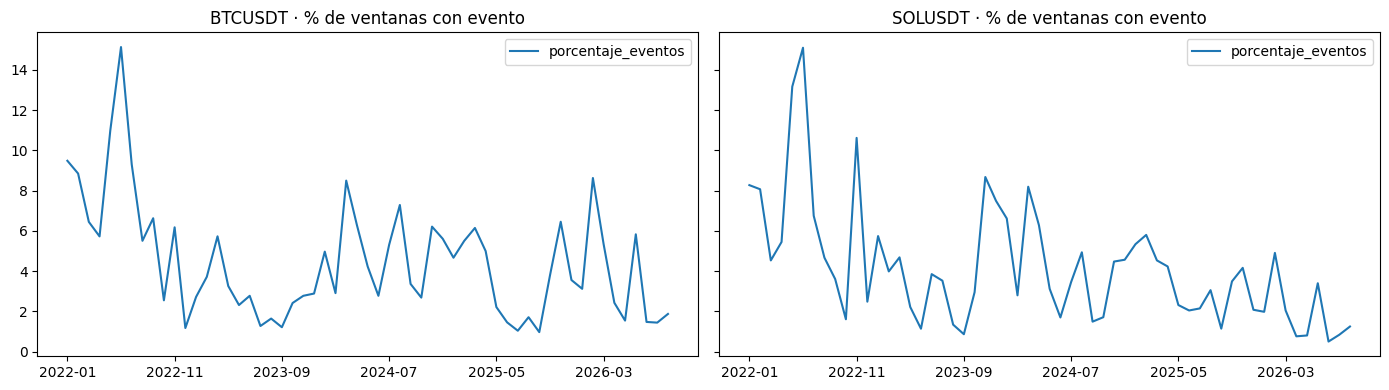

,symbol,mes,porcentaje_eventos
102,SOLUSDT,2026-04,0.763889
103,BTCUSDT,2026-04,2.430556
104,SOLUSDT,2026-05,0.806452
105,BTCUSDT,2026-05,1.545699
106,SOLUSDT,2026-06,3.402778
107,BTCUSDT,2026-06,5.833333
108,SOLUSDT,2026-07,0.504032
109,BTCUSDT,2026-07,1.478495
110,SOLUSDT,2026-08,0.840054
111,BTCUSDT,2026-08,1.444892


In [8]:
datos = (spark.read.parquet(str(ML / "model_dataset"))
    .withColumn("mes", F.date_format(F.timestamp_millis("open_ms"), "yyyy-MM"))
    .withColumn("hora_utc", F.hour(F.timestamp_millis("open_ms")))).cache()
mensual = datos.groupBy("symbol", "mes").agg((100 * F.avg("target_crash")).alias("porcentaje_eventos")).orderBy("mes").toPandas()
fig, ejes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for eje, (activo, grupo) in zip(ejes, mensual.groupby("symbol")):
    grupo.plot(x="mes", y="porcentaje_eventos", ax=eje, title=f"{activo} · % de ventanas con evento")
    eje.set_xlabel("")
plt.tight_layout(); plt.show()
mensual.groupby("symbol").tail(6)

**Diagnóstico:** ¿las caídas fuertes se concentran cuando el mercado ya está volátil? Se agrupa por quintil de volatilidad reciente (`rv15`).

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


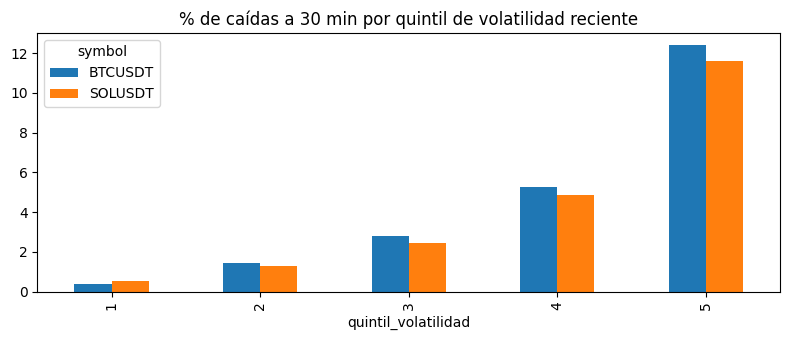

,symbol,quintil_volatilidad,porcentaje_caidas
0,BTCUSDT,1,0.396515
1,BTCUSDT,2,1.462902
2,BTCUSDT,3,2.820752
3,BTCUSDT,4,5.238968
4,BTCUSDT,5,12.394485
5,SOLUSDT,1,0.555739
6,SOLUSDT,2,1.300769
7,SOLUSDT,3,2.430305
8,SOLUSDT,4,4.860610
9,SOLUSDT,5,11.604783


In [9]:
quintil = Window.partitionBy("symbol").orderBy("rv15")
diag = (datos.withColumn("quintil_volatilidad", F.ntile(5).over(quintil))
    .groupBy("symbol", "quintil_volatilidad").agg((100 * F.avg("target_crash")).alias("porcentaje_caidas"))
    .orderBy("symbol", "quintil_volatilidad").toPandas())
diag.pivot(index="quintil_volatilidad", columns="symbol", values="porcentaje_caidas").plot.bar(
    figsize=(8, 3.5), title="% de caídas a 30 min por quintil de volatilidad reciente"); plt.tight_layout(); plt.show()
diag

## 6. Modelo predictivo distribuido (Spark MLlib)

Partición temporal sin fuga de información: **entrenamiento 2022–2024**, **validación 2025**, **prueba enero–septiembre 2026**, con un embargo de 30 minutos entre tramos. El ganador se elige solo con validación; la prueba se usa una vez, al final.

In [10]:
base = datos.withColumnRenamed("target_crash", "label")
COLUMNAS = FEATURES

In [11]:
entrenamiento = base.filter(F.col("open_ms") + 1800000 < TRAIN_END).cache()
validacion = base.filter((F.col("open_ms") >= TRAIN_END) & (F.col("open_ms") + 1800000 < VALIDATION_END)).cache()
prueba = base.filter(F.col("open_ms") >= VALIDATION_END).cache()
print({"entrenamiento": entrenamiento.count(), "validacion": validacion.count(), "prueba": prueba.count()})

{'entrenamiento': 210392, 'validacion': 70076, 'prueba': 52412}


In [12]:
ensamblador = VectorAssembler(inputCols=COLUMNAS, outputCol="features")
escalador = StandardScaler(inputCol="features", outputCol="scaled", withMean=True, withStd=True)
CANDIDATOS = {
    "logistica_l2": [ensamblador, escalador, LogisticRegression(featuresCol="scaled", regParam=0.01, maxIter=60)],
    "logistica_elasticnet": [ensamblador, escalador, LogisticRegression(featuresCol="scaled", regParam=0.05, elasticNetParam=0.5, maxIter=60)],
    "random_forest": [ensamblador, RandomForestClassifier(numTrees=30, maxDepth=6, minInstancesPerNode=30, seed=26)],
}
prevalencia = {r.symbol: r.p for r in entrenamiento.groupBy("symbol").agg(F.avg("label").alias("p")).collect()}
mapa_prevalencia = F.create_map(*[x for s, p in prevalencia.items() for x in (F.lit(s), F.lit(p))])

def con_probabilidad(df):
    return df.withColumn("p", vector_to_array("probability")[1])

def mejor_umbral(df):
    filas = df.select("p", "label").toPandas()
    mejor = (0.0, 0.5)
    for u in filas["p"].quantile([i / 100 for i in range(5, 100)]).unique():
        pred = filas["p"] >= u
        tp = int((pred & (filas.label == 1)).sum()); fp = int((pred & (filas.label == 0)).sum())
        fn = int((~pred & (filas.label == 1)).sum())
        f1 = 2 * tp / max(1, 2 * tp + fp + fn)
        mejor = max(mejor, (f1, float(u)))
    return mejor[1]

def evaluar(df, umbral):
    auc_roc = BinaryClassificationEvaluator(rawPredictionCol="p", metricName="areaUnderROC").evaluate(df)
    auc_pr = BinaryClassificationEvaluator(rawPredictionCol="p", metricName="areaUnderPR").evaluate(df)
    r = df.withColumn("pos", (F.col("p") >= umbral).cast("int")).agg(
        F.avg((F.col("p") - F.col("label")) ** 2).alias("brier"),
        F.sum(((F.col("pos") == 1) & (F.col("label") == 1)).cast("int")).alias("tp"),
        F.sum(((F.col("pos") == 1) & (F.col("label") == 0)).cast("int")).alias("fp"),
        F.sum(((F.col("pos") == 0) & (F.col("label") == 1)).cast("int")).alias("fn")).first()
    precision = r.tp / max(1, r.tp + r.fp); recall = r.tp / max(1, r.tp + r.fn)
    return {"auc_roc": float(auc_roc), "auc_pr": float(auc_pr), "brier": float(r.brier), "precision": precision,
            "recall": recall, "f1": 2 * precision * recall / max(1e-9, precision + recall), "umbral": umbral}

modelos, umbrales, resultados_val = {}, {}, {}
referencia_val = validacion.withColumn("p", mapa_prevalencia[F.col("symbol")])
resultados_val["referencia"] = evaluar(referencia_val, 0.5)
for nombre, etapas in CANDIDATOS.items():
    modelos[nombre] = Pipeline(stages=etapas).fit(entrenamiento)
    puntuado = con_probabilidad(modelos[nombre].transform(validacion)).cache()
    umbrales[nombre] = mejor_umbral(puntuado)
    resultados_val[nombre] = evaluar(puntuado, umbrales[nombre])
tabla_val = pd.DataFrame(resultados_val).T.sort_values("auc_pr", ascending=False)
ganador = max(CANDIDATOS, key=lambda n: resultados_val[n]["auc_pr"])
print("Referencia: prevalencia histórica por activo | ganador en validación (AUC-PR):", ganador)
tabla_val

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Referencia: prevalencia histórica por activo | ganador en validación (AUC-PR): logistica_l2


,auc_roc,auc_pr,brier,precision,recall,f1,umbral
logistica_l2,0.795208,0.125059,0.032255,0.142857,0.373704,0.206699,0.082155
logistica_elasticnet,0.753496,0.107627,0.032950,0.141260,0.246371,0.179565,0.058017
random_forest,0.704496,0.105557,0.032912,0.112815,0.393613,0.175367,0.049447
referencia,0.506765,0.035086,0.033468,0.000000,0.000000,0.000000,0.500000


Prueba 2026: AUC-PR logistica_l2 0.103 vs referencia 0.033


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


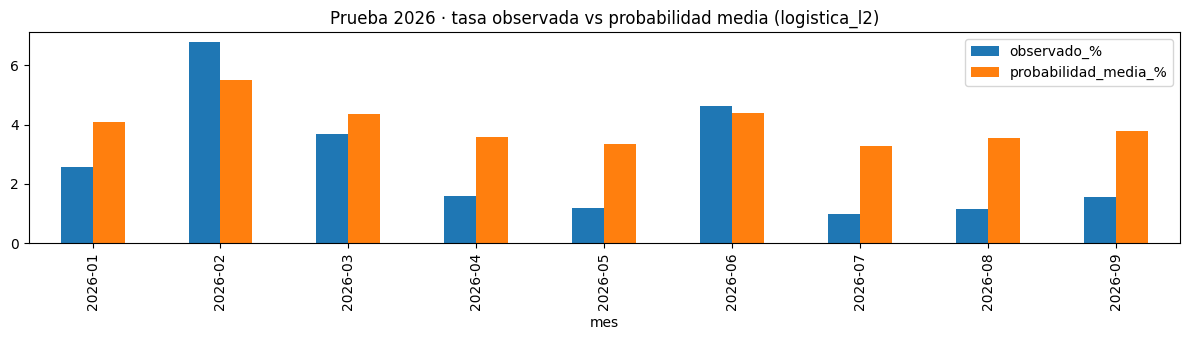

,auc_roc,auc_pr,brier,precision,recall,f1,umbral
logistica_l2,0.789667,0.103077,0.025044,0.14646,0.239681,0.181818,0.082155
referencia,0.581250,0.033262,0.026218,0.00000,0.000000,0.000000,0.500000


In [13]:
predicciones = con_probabilidad(modelos[ganador].transform(prueba)).cache()
resultados_test = {ganador: evaluar(predicciones, umbrales[ganador]),
                   "referencia": evaluar(prueba.withColumn("p", mapa_prevalencia[F.col("symbol")]), 0.5)}
print(f"Prueba 2026: AUC-PR {ganador} {resultados_test[ganador]['auc_pr']:.3f} vs referencia {resultados_test['referencia']['auc_pr']:.3f}")
mensual_test = (predicciones.withColumn("mes", F.date_format(F.timestamp_millis("open_ms"), "yyyy-MM"))
    .groupBy("mes").agg((100 * F.avg("label")).alias("observado_%"), (100 * F.avg("p")).alias("probabilidad_media_%"))
    .orderBy("mes").toPandas())
mensual_test.plot.bar(x="mes", figsize=(12, 3.5), title=f"Prueba 2026 · tasa observada vs probabilidad media ({ganador})")
plt.tight_layout(); plt.show()
pd.DataFrame(resultados_test).T

In [14]:
# Se guarda el modelo que ganó en validación (no el primero entrenado) y se comprueba que recarga.
ruta = str(SALIDA / "modelo_ganador")
modelos[ganador].write().overwrite().save(ruta)
recargado = PipelineModel.load(ruta)
print("Modelo guardado y recargado:", ruta, "| etapas:", [type(s).__name__ for s in recargado.stages])

Modelo guardado y recargado: /opt/u1-dimensiones/artifacts/caidas/modelo_ganador | etapas: ['VectorAssembler', 'StandardScalerModel', 'LogisticRegressionModel']


## 7. Registro de la verificación

In [15]:
verificacion = {"dimension": "caidas", "integrante": "Julmer Quispe Apaza", "status": "PASS",
    "filas_crudas": filas_crudas, "filas_particion": filas_particion, "duplicados": duplicados,
    "modelo_ganador": ganador, "metricas_validacion": resultados_val, "metricas_prueba": resultados_test,
    "modelo_guardado": str(SALIDA / "modelo_ganador")}
(SALIDA / "verificacion_u1.json").write_text(json.dumps(verificacion, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print(json.dumps(verificacion, indent=2, ensure_ascii=False, default=float))
spark.stop()

{
  "dimension": "caidas",
  "integrante": "Julmer Quispe Apaza",
  "status": "PASS",
  "filas_crudas": 43200,
  "filas_particion": 43200,
  "duplicados": 0,
  "modelo_ganador": "logistica_l2",
  "metricas_validacion": {
    "referencia": {
      "auc_roc": 0.5067653234579079,
      "auc_pr": 0.03508564346172097,
      "brier": 0.03346842322878303,
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "umbral": 0.5
    },
    "logistica_l2": {
      "auc_roc": 0.795207938025619,
      "auc_pr": 0.12505937845831927,
      "brier": 0.03225485195033703,
      "precision": 0.14285714285714285,
      "recall": 0.37370385732061384,
      "f1": 0.20669878412479925,
      "umbral": 0.08215476385323514
    },
    "logistica_elasticnet": {
      "auc_roc": 0.7534957652864656,
      "auc_pr": 0.1076265440995896,
      "brier": 0.03294988802518288,
      "precision": 0.1412604042806183,
      "recall": 0.24637080049771878,
      "f1": 0.1795646916565901,
      "umbral": 0.05801686823

## 8. Respuesta a la pregunta de la dimensión

**Pregunta U1 (Julmer):** ¿Con qué frecuencia BTC y SOL tuvieron caídas fuertes a 30 minutos (dentro del 5 % de peores caídas de su historial) y en qué condiciones de mercado ocurren más, y qué probabilidad hay de una caída así en los próximos 30 minutos?

| | Respuesta con los datos 2022–2026 |
|---|---|
| **Indicador** | % de ventanas de 30 min con rendimiento ≤ P5 del entrenamiento (BTC −0,558 %, SOL −1,116 %) |
| **¿Con qué frecuencia?** | En todo el periodo, **BTC 4,5 %** y **SOL 4,2 %** de las ventanas: cerca del 5 % que define el umbral |
| **¿En qué meses más?** | **Junio de 2022** (15 % en ambos activos) y **mayo de 2022** (11 % BTC, 13 % SOL): triple de lo normal, en plena crisis del mercado |
| **¿En qué condiciones ocurren más?** | Con la **volatilidad reciente más alta** (quintil 5) las caídas fuertes llegan a **12,4 % en BTC y 11,6 % en SOL**; con la más baja (quintil 1), apenas **0,4 % y 0,6 %**: unas **30 veces menos** |
| **¿Qué probabilidad hay en 30 min? (predictiva)** | La **regresión logística L2** detecta las caídas con **AUC-PR 0,103** en la prueba de 2026, frente a **0,033** de la frecuencia histórica: **3 veces mejor**. Es un evento raro: recall ~24 % y precisión ~15 % |
| **Decisión que habilita** | Reducir exposición o vigilar de cerca cuando la probabilidad supera el umbral de alerta (5,8 % en vivo) |
| **Continúa en U2** | La misma logística, calibrada, corre en Spark cada minuto: panel *Caída fuerte · Julmer* en Grafana |